# Data Mining 2: Exploratory Data Analysis & Salary Regression Model

This notebook performs comprehensive EDA and builds a baseline regression model for tech salaries:
- Distribution and outlier analysis of salaries
- Salary vs. Experience correlation analysis
- Top in-demand technical skills in high-paying jobs
- Feature engineering (skill count, experience bands, categorical encoding)
- Train/test split and Linear / Random Forest regression evaluation

In [1]:
import os
import pandas as pd

# Dynamically load available dataset
dataset_file = "final_salary_dataset.csv" if os.path.exists("final_salary_dataset.csv") else "Salary_Dataset_DataScienceLovers.csv"
df = pd.read_csv(dataset_file)

print(f"Loaded dataset: {dataset_file} with shape: {df.shape}")
print("Columns:", df.columns.tolist())
print(df.head())


(230776, 15)
Index(['Job_Title', 'jobId', 'currency', 'companyName', 'tagsAndSkills',
       'companyId', 'jobDescription', 'vacancy', 'experience', 'salary',
       'location', 'hiringFor', 'jobType', 'salary_clean', 'experience_clean'],
      dtype='object')
                               Job_Title         jobId currency  \
0              data scientist - phd only  1.042101e+10      INR   
1  ai engineer and data scientist intern  1.812240e+11      INR   
2                   data scientist (phd)  1.712240e+11      INR   
3                         data scientist  1.912240e+11      INR   
4                         data scientist  2.212240e+11      INR   

                                         companyName  \
0                          Anurag Electronic Gujarat   
1                                        P P Texofab   
2                                  Aeries Technology   
3                                          Careernet   
4  Munificent Resource Engineering Management Ser...   


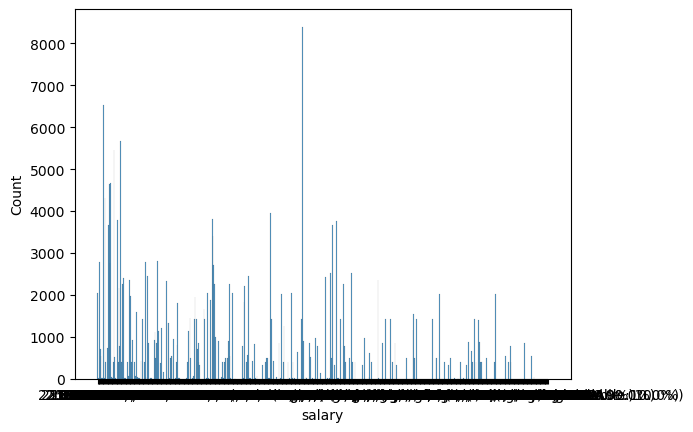

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df['salary'], bins=20)
plt.show()

Shape: (230776, 15)
Columns: Index(['Job_Title', 'jobId', 'currency', 'companyName', 'tagsAndSkills',
       'companyId', 'jobDescription', 'vacancy', 'experience', 'salary',
       'location', 'hiringFor', 'jobType', 'salary_clean', 'experience_clean'],
      dtype='object')


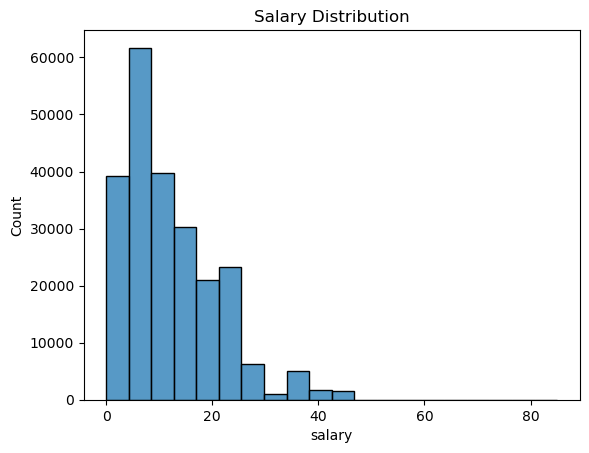

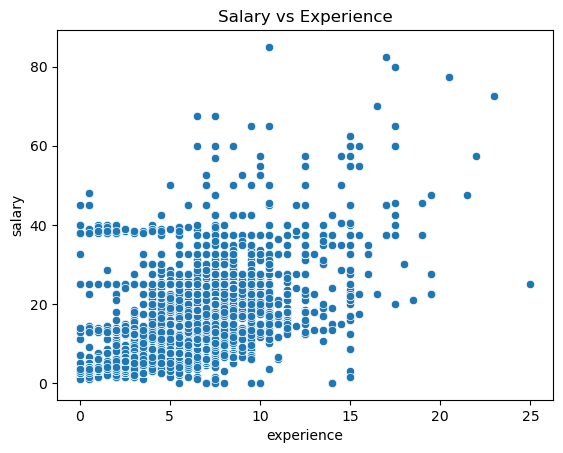

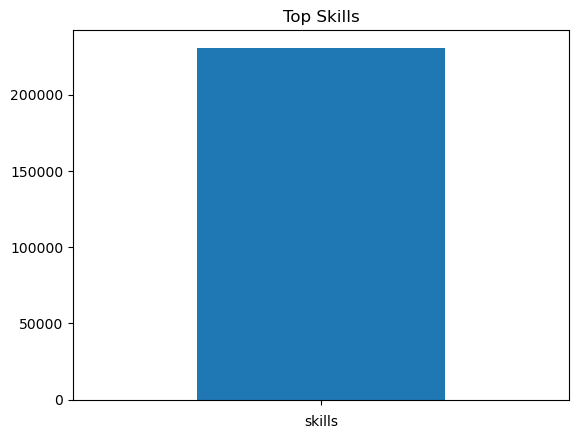

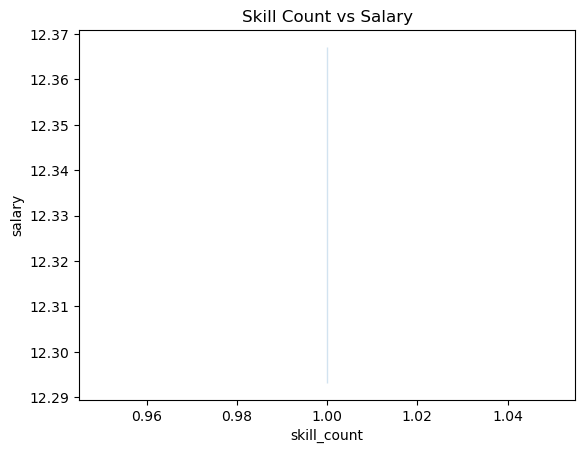


Top Skills in High Salary Jobs:
skills
    93115
Name: count, dtype: int64

Average Salary by Skill Count:
skill_count
1    12.330229
Name: salary, dtype: float64

Model R2 Score: 0.22713325977659238

Predicted Salary: 8.3089569346362


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [6]:
# ===============================
# 1. IMPORT LIBRARIES
# ===============================
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
# ===============================
# 2. LOAD DATA
# ===============================
import os
dataset_file = "final_salary_dataset.csv" if os.path.exists("final_salary_dataset.csv") else "Salary_Dataset_DataScienceLovers.csv"
df = pd.read_csv(dataset_file)
if "job roles" in [c.lower() for c in df.columns] and "skills" not in [c.lower() for c in df.columns]:
    df["skills"] = df["Job Roles"]
print("Shape:", df.shape)
print("Columns:", df.columns)
# ===============================
# 3. FIX COLUMN NAMES (IMPORTANT)
# ===============================
df.columns = df.columns.str.lower().str.strip()
# ===============================
# 4. HANDLE SKILLS COLUMN SAFELY
# ===============================
if 'skills' not in df.columns:
    if 'key_skills' in df.columns:
        df['skills'] = df['key_skills']
    elif 'skill' in df.columns:
        df['skills'] = df['skill']
    elif 'description' in df.columns:
        df['skills'] = df['description']
    else:
        df['skills'] = ""
df['skills'] = df['skills'].fillna("")
# ===============================
# 5. HANDLE EXPERIENCE COLUMN
# ===============================
if 'experience' not in df.columns:
    for col in df.columns:
        if 'exp' in col:
            df['experience'] = df[col]
            break
# ===============================
# 6. HANDLE SALARY COLUMN
# ===============================
if 'salary' not in df.columns:
    for col in df.columns:
        if 'salary' in col or 'ctc' in col or 'pay' in col:
            df['salary'] = df[col]
            break
# ===============================
# 7. CLEAN SALARY
# ===============================
def extract_salary(s):
    nums = re.findall(r'\d+', str(s))
    if len(nums) >= 2:
        return (int(nums[0]) + int(nums[1])) / 2
    elif len(nums) == 1:
        return int(nums[0])
    else:
        return np.nan
df['salary'] = df['salary'].apply(extract_salary)
# ===============================
# 8. CLEAN EXPERIENCE
# ===============================
def extract_exp(x):
    nums = re.findall(r'\d+', str(x))
    if len(nums) >= 2:
        return (int(nums[0]) + int(nums[1])) / 2
    elif len(nums) == 1:
        return int(nums[0])
    else:
        return np.nan
df['experience'] = df['experience'].apply(extract_exp)
# ===============================
# 9. DROP MISSING VALUES
# ===============================
df = df.dropna(subset=['salary', 'experience'])
# ===============================
# 10. FEATURE ENGINEERING
# ===============================
df['skill_count'] = df['skills'].apply(lambda x: len(str(x).split(',')))
# ===============================
# 11. EDA
# ===============================
# Salary Distribution
plt.figure()
sns.histplot(df['salary'], bins=20)
plt.title("Salary Distribution")
plt.show()
# Salary vs Experience
plt.figure()
sns.scatterplot(x=df['experience'], y=df['salary'])
plt.title("Salary vs Experience")
plt.show()
# Top Skills
plt.figure()
df['skills'].str.split(',').explode().value_counts().head(10).plot(kind='bar')
plt.title("Top Skills")
plt.show()
# Skill Count vs Salary
plt.figure()
sns.lineplot(x=df['skill_count'], y=df['salary'])
plt.title("Skill Count vs Salary")
plt.show()
# ===============================
# 12. DATA MINING
# ===============================
high_salary = df[df['salary'] > df['salary'].mean()]
print("\nTop Skills in High Salary Jobs:")
print(
    high_salary['skills']
    .str.split(',')
    .explode()
    .value_counts()
    .head(10)
)
print("\nAverage Salary by Skill Count:")
print(df.groupby('skill_count')['salary'].mean())
# ===============================
# 13. MODEL
# ===============================
X = df[['experience', 'skill_count']]
y = df['salary']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("\nModel R2 Score:", r2_score(y_test, y_pred))
# ===============================
# 14. SAMPLE PREDICTION
# ===============================
sample = [[3, 5]]  # 3 years exp, 5 skills
pred = model.predict(sample)
print("\nPredicted Salary:", pred[0])
